# Multiple linear regression

Multiple linear regression models the relationship between several features and a single variable. 
This technique simultaneously models multiple relationships which it treats independent of each other.

Multiple linear regression expects features to be independent of each other otherwise it creates misleading predictions.

# Goodness of fit: R<sup>2</sup>

R<sup>2</sup> is a value between 0 and 1 that tells how well linear regression model fits the data. 

Limitations of R<sup>2</sup>:
- More data we have higher the R<sup>2</sup>
- R<sup>2</sup> does not tell us how it will work with unseen data
- R<sup>2</sup> does not tell us the direction of relationship. It does not tell us the direction of slope.

In [1]:
import pandas as pd

dataset = pd.read_csv('doggy-illness.csv', delimiter='\t')
dataset.head()

,male,attended_training,age,body_fat_percentage,core_temperature,ate_at_tonys_steakhouse,needed_intensive_care,protein_content_of_last_meal
0,0,1,6.9,38,38.423169,0,0,7.66
1,0,1,5.4,32,39.015998,0,0,13.36
2,1,1,5.4,12,39.148341,0,0,12.90
3,1,0,4.8,23,39.060049,0,0,13.45
4,1,0,4.8,15,38.655439,0,0,10.53


<Figure size 800x500 with 0 Axes>

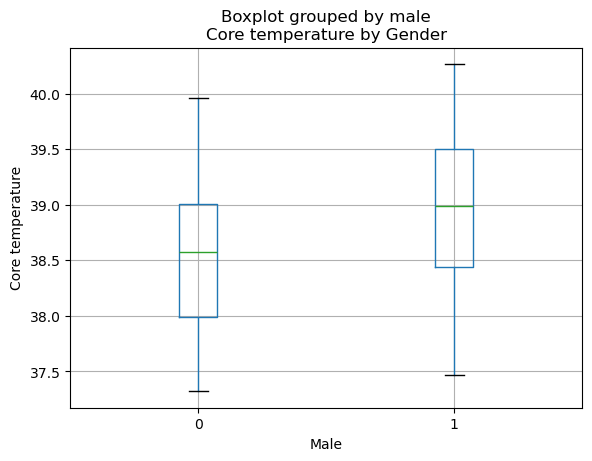

<Figure size 800x500 with 0 Axes>

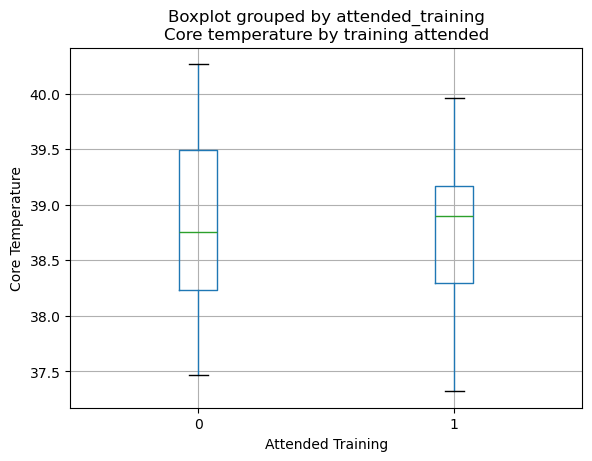

<Figure size 800x500 with 0 Axes>

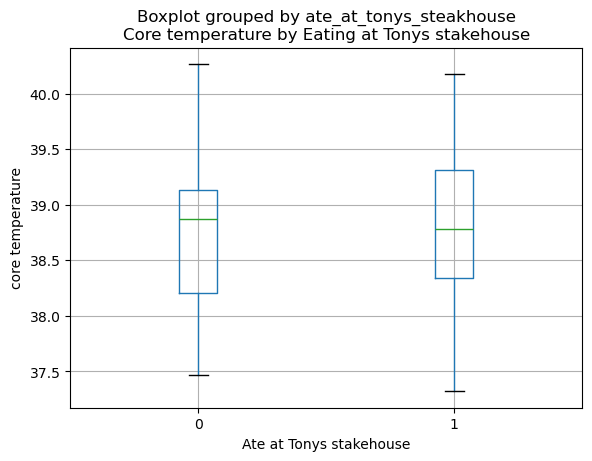

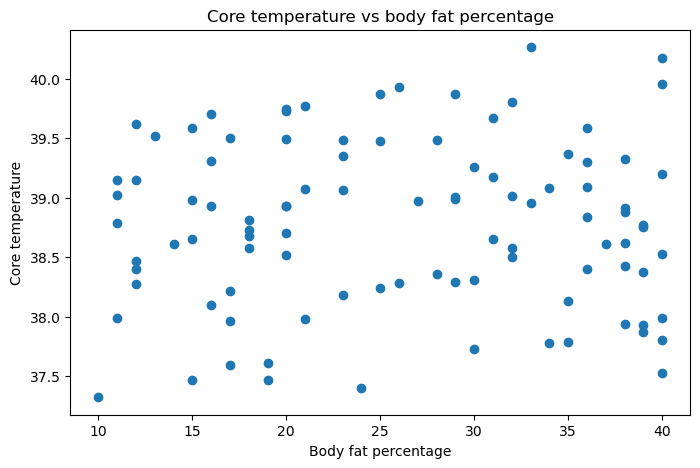

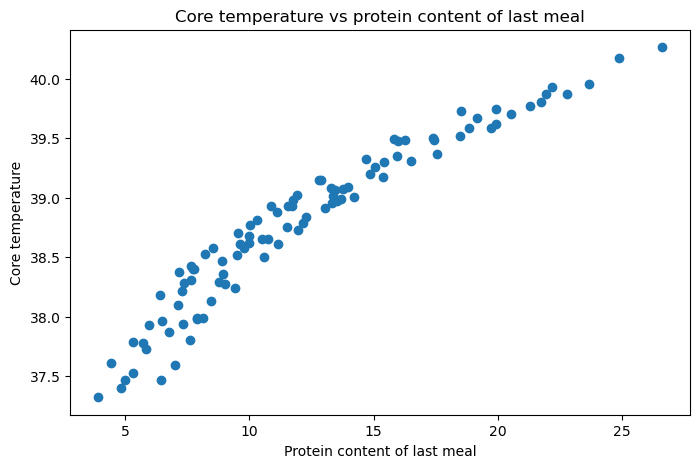

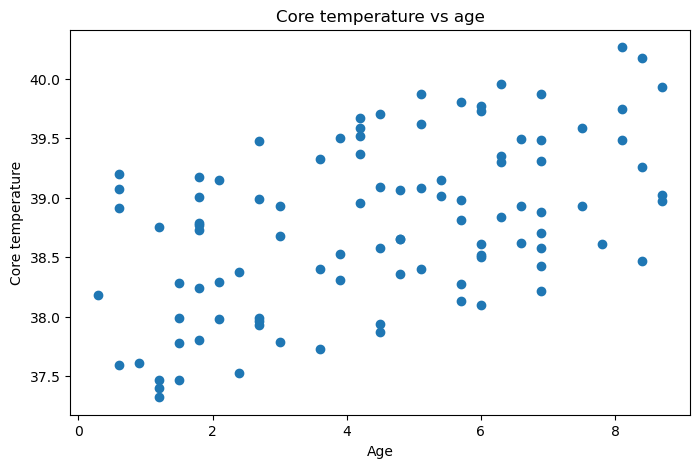

In [5]:
# Data visualization

import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))
dataset.boxplot(column='core_temperature', by='male')
plt.title('Core temperature by Gender')
plt.xlabel('Male')
plt.ylabel('Core temperature')
plt.show()

plt.figure(figsize=(8,5))
dataset.boxplot(column='core_temperature', by='attended_training')
plt.title('Core temperature by training attended')
plt.xlabel('Attended Training')
plt.ylabel('Core Temperature')
plt.show()

plt.figure(figsize=(8,5))
dataset.boxplot(column='core_temperature', by='ate_at_tonys_steakhouse')
plt.title('Core temperature by Eating at Tony''s stakehouse')
plt.xlabel('Ate at Tonys stakehouse')
plt.ylabel('core temperature')
plt.show()

plt.figure(figsize=(8,5))
plt.scatter(dataset.body_fat_percentage, dataset.core_temperature)
plt.title('Core temperature vs body fat percentage')
plt.xlabel('Body fat percentage')
plt.ylabel('Core temperature')
plt.show()

plt.figure(figsize=(8,5))
plt.scatter(dataset.protein_content_of_last_meal, dataset.core_temperature)
plt.title('Core temperature vs protein content of last meal')
plt.xlabel('Protein content of last meal')
plt.ylabel('Core temperature')
plt.show()

plt.figure(figsize=(8,5))
plt.scatter(dataset.age, dataset.core_temperature)
plt.title('Core temperature vs age')
plt.xlabel('Age')
plt.ylabel('Core temperature')
plt.show()




male
R-squared:  0.0999007443071992


/var/folders/lz/9ztyyq913n1_6xkj9g8_jlg40000gn/T/ipykernel_3524/3897034220.py:20: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  y_vals = simple_model.params[1] * x_vals + simple_model.params[0]


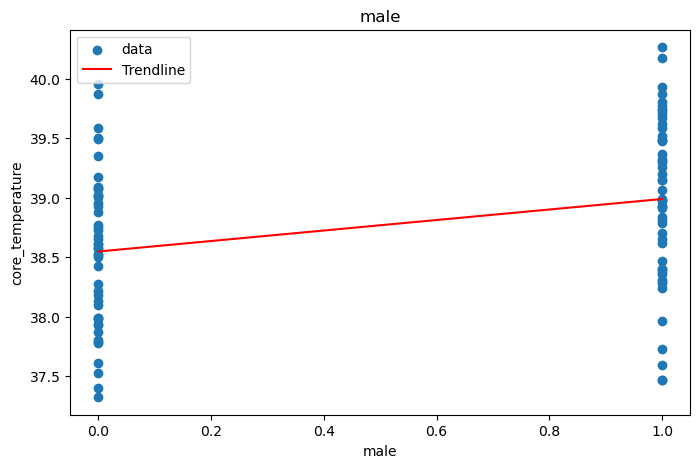

age
R-squared:  0.2648116081342463


/var/folders/lz/9ztyyq913n1_6xkj9g8_jlg40000gn/T/ipykernel_3524/3897034220.py:20: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  y_vals = simple_model.params[1] * x_vals + simple_model.params[0]


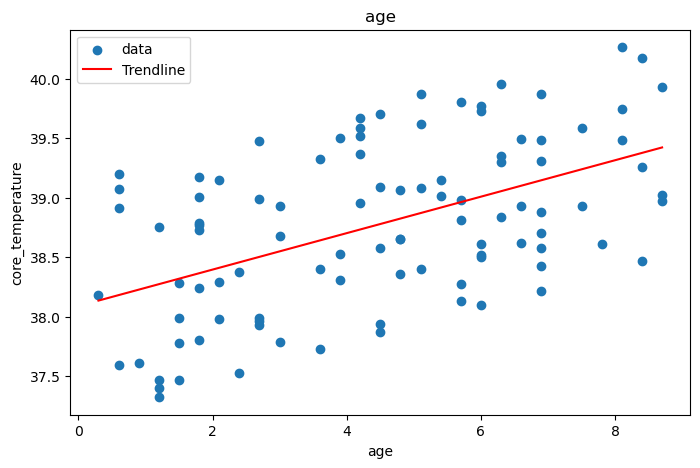

protein_content_of_last_meal
R-squared:  0.9155158150005711


/var/folders/lz/9ztyyq913n1_6xkj9g8_jlg40000gn/T/ipykernel_3524/3897034220.py:20: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  y_vals = simple_model.params[1] * x_vals + simple_model.params[0]


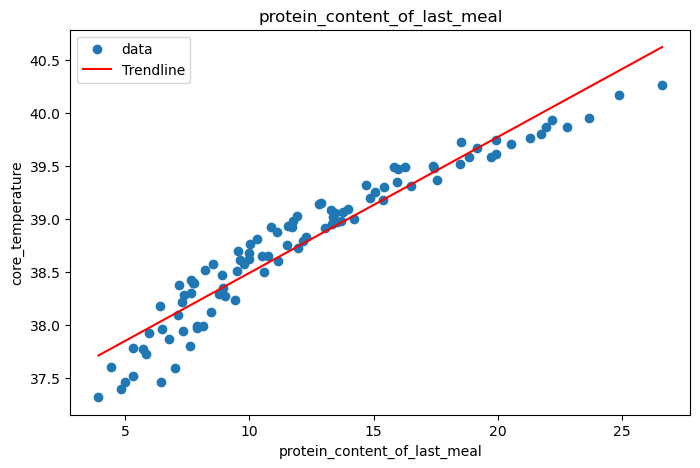

body_fat_percentage
R-squared:  0.0002080900263790042


/var/folders/lz/9ztyyq913n1_6xkj9g8_jlg40000gn/T/ipykernel_3524/3897034220.py:20: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  y_vals = simple_model.params[1] * x_vals + simple_model.params[0]


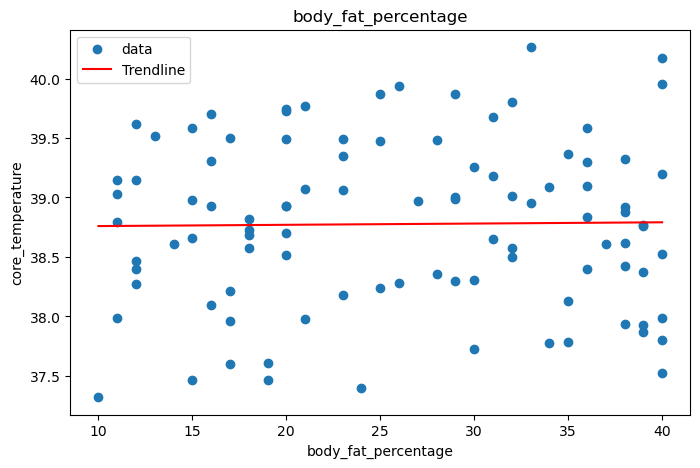

In [7]:
# Simple linear regression
# From above illustration we can conclude that male, age, body fat percentage and protein content of last meal
# are most useful features

import statsmodels.formula.api as smf
import matplotlib.pyplot as plt
import numpy as np

for feature in ['male', 'age', 'protein_content_of_last_meal', 'body_fat_percentage']:
    formula = 'core_temperature ~ '+ feature
    simple_model = smf.ols(formula=formula, data=dataset).fit()

    print(feature)
    print('R-squared: ', simple_model.rsquared)

    plt.figure(figsize=(8, 5))
    plt.scatter(dataset[feature], dataset.core_temperature, label='data')

    x_vals = np.linspace(dataset[feature].min(), dataset[feature].max(), 100)
    y_vals = simple_model.params[1] * x_vals + simple_model.params[0]

    plt.plot(x_vals, y_vals, color='red', label='Trendline')

    plt.xlabel(feature)
    plt.ylabel('core_temperature')
    plt.title(feature)
    plt.legend()
    plt.show()




In [ ]:
# Multiple linear regression 

model = smf.ols('core_temperature ~ age + male', data= dataset).fit()
print('R-squared: ', model.rsquared)

# got better result when using age and gender feature together

R-squared:  0.3148512699768017


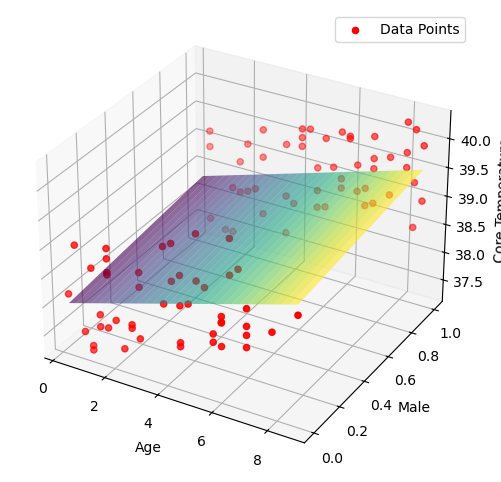

In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

def predict1(age, male):
    df = pd.DataFrame(dict(age=age.ravel(), male=male.ravel()))
    return model.predict(df).values.reshape(age.shape)

age_range = np.linspace(dataset.age.min(), dataset.age.max(), 30)
male_range = np.array([0,1])

age_grid, male_grid = np.meshgrid(age_range, male_range)
z_vals = predict1(age_grid, male_grid)

fig = plt.figure(figsize=(10,6))
ax=fig.add_subplot(111, projection='3d')

ax.plot_surface(age_grid, male_grid, z_vals, alpha=0.6, cmap='viridis')
ax.scatter(dataset.age, dataset.male, dataset.core_temperature, color='red', label='Data Points')

ax.set_xlabel('Age')
ax.set_ylabel('Male')
ax.set_zlabel('Core Temperature')
plt.legend()
plt.show()


In [12]:
model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:       core_temperature   R-squared:                       0.315
Model:                            OLS   Adj. R-squared:                  0.300
Method:                 Least Squares   F-statistic:                     21.83
Date:                Tue, 04 Nov 2025   Prob (F-statistic):           1.58e-08
Time:                        02:20:12   Log-Likelihood:                -85.295
No. Observations:                  98   AIC:                             176.6
Df Residuals:                      95   BIC:                             184.3
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     37.9793      0.135    282.094      0.000      37.712      38.247
age            0.1406      0.026      5.459      0.000       0.089       0.192
male           0.3182      0.121      2.634      0.010       0.078       0.558
==============================================================================
Omnibus:                       21.610   Durbin-Watson:                   2.369
Prob(Omnibus):                  0.000   Jarque-Bera (JB):                5.227
Skew:                           0.121   Prob(JB):                       0.0733
Kurtosis:                       1.895   Cond. No.                         12.9
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""